# 02 · Modelado y evaluación

Partimos de las decisiones del EDA (`01_eda.ipynb`). El objetivo aquí es responder a tres preguntas:

1. ¿Cuánto mejora un modelo sobre la **regla de negocio** ("sin seguro de vehículo y con daños previos")?
2. ¿Compensa un modelo complejo (XGBoost) frente a uno simple (regresión logística)?
3. ¿Qué le decimos a negocio con los resultados?

**Esquema de validación:**

- Se aparta un **20 % como test final**, estratificado. No se usa para tomar ninguna decisión.
- Todas las comparaciones y decisiones se toman con **validación cruzada de 5 particiones** sobre el 80 % restante.
- Al final se evalúa **una sola vez** en test.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_validate

from xsell.config import CV_FOLDS, SEED
from xsell.data import load_data, split_data
from xsell.evaluate import capture_at, lift_table, ranking_metrics
from xsell.features import EXCLUDED
from xsell.models import build_logistic, build_xgboost

# KBinsDiscretizer avisa de tramos de edad muy pequeños; no afecta al resultado.
warnings.filterwarnings("ignore", category=UserWarning)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "axes.axisbelow": True,
})
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Datos y partición

In [2]:
df = load_data("../data/raw/train.csv")
X_train, X_test, y_train, y_test = split_data(df)

print(f"Entrenamiento: {len(X_train):,} clientes, {y_train.mean():.2%} interesados")
print(f"Test final:    {len(X_test):,} clientes, {y_test.mean():.2%} interesados")

Entrenamiento: 304,887 clientes, 12.26% interesados
Test final:    76,222 clientes, 12.26% interesados


## 2. Baseline: la regla de negocio

La regla no se entrena, así que se puede medir directamente. La expresamos como un score 0/1 para poder compararla con los modelos con las mismas métricas.

In [3]:
def regla(X):
    """1 si el cliente no tiene seguro de vehículo y ha tenido daños; 0 en otro caso."""
    return ((X["Previously_Insured"] == 0) & (X["Vehicle_Damage"] == "Yes")).astype(int)


ranking_metrics(y_train, regla(X_train))

{'pr_auc': 0.2470540145444498, 'roc_auc': 0.7837907997449473}

## 3. Comparación de modelos con validación cruzada

In [4]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)


def evaluar_cv(modelo):
    """Media y desviación de PR-AUC y ROC-AUC en las particiones de validación."""
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["average_precision", "roc_auc"])
    return {
        "pr_auc": r["test_average_precision"].mean(),
        "pr_auc_std": r["test_average_precision"].std(),
        "roc_auc": r["test_roc_auc"].mean(),
        "roc_auc_std": r["test_roc_auc"].std(),
    }


candidatos = {
    "logistica": build_logistic(),
    "xgboost": build_xgboost(),
    "logistica_sin_gender": build_logistic(drop=("Gender",)),
    "xgboost_sin_gender": build_xgboost(drop=("Gender",)),
}
resultados_cv = pd.DataFrame({nombre: evaluar_cv(m) for nombre, m in candidatos.items()}).T
resultados_cv

,pr_auc,pr_auc_std,roc_auc,roc_auc_std
logistica,0.3567,0.0027,0.8531,0.0013
xgboost,0.3679,0.0032,0.8568,0.0016
logistica_sin_gender,0.3567,0.0026,0.8530,0.0013
xgboost_sin_gender,0.3675,0.0027,0.8566,0.0016


**Lectura:**

- **Los dos modelos baten claramente a la regla** (PR-AUC ~0,36 frente a 0,25).
- **XGBoost supera a la logística por poco** (0,368 frente a 0,357). La diferencia es pequeña pero consistente: es unas 4 veces la desviación entre particiones.
- **`Gender` no aporta nada**: quitarla cambia el PR-AUC en la cuarta cifra decimal, muy por debajo de la variación entre particiones. **Decisión: se excluye del modelo** (`EXCLUDED` en `features.py`). Es una variable sensible y no cuesta nada prescindir de ella.
- La desviación entre particiones es baja (~0,003): los resultados son estables.

## 4. Evaluación final en test

In [5]:
modelos = {
    "logistica": build_logistic(drop=EXCLUDED).fit(X_train, y_train),
    "xgboost": build_xgboost(drop=EXCLUDED).fit(X_train, y_train),
}

scores = {"regla": regla(X_test)}
for nombre, modelo in modelos.items():
    scores[nombre] = modelo.predict_proba(X_test)[:, 1]

pd.DataFrame({nombre: ranking_metrics(y_test, s) for nombre, s in scores.items()}).T

,pr_auc,roc_auc
regla,0.2477,0.7846
logistica,0.3539,0.8528
xgboost,0.3681,0.8570


**Lectura:** las métricas en test coinciden con las de validación cruzada (XGBoost: 0,368 en ambos casos). No hay señal de sobreajuste al proceso de selección.

Como referencia: un PR-AUC de 0,37 con una tasa base del 12,3 % significa que el modelo ordena unas 3 veces mejor que el azar, pero está lejos de ser perfecto. El interés de un cliente no se puede predecir con certeza con estas variables.

### 4.1 Modelo frente a regla, a igual volumen de contactos

La regla solo ofrece un volumen de contactos (el segmento entero). El modelo permite elegir cualquier volumen. Comparamos cuántos interesados se capturan contactando al mismo porcentaje de la cartera.

In [6]:
pct_regla = regla(X_test).mean()
captura_regla = y_test[regla(X_test) == 1].sum() / y_test.sum()
print(f"La regla contacta al {pct_regla:.1%} de la cartera y captura el {captura_regla:.1%} de los interesados\n")

volumenes = [0.10, 0.20, 0.30, 0.40, pct_regla]
captura = pd.DataFrame(
    {nombre: [capture_at(y_test, scores[nombre], p) for p in volumenes] for nombre in modelos},
    index=[f"{p:.1%}" for p in volumenes],
)
captura.index.name = "cartera contactada"
# Dentro de su segmento la regla no ordena: contactar a una parte equivale a elegir al azar.
captura["regla (al azar dentro del segmento)"] = [min(p / pct_regla, 1) * captura_regla for p in volumenes]
captura

La regla contacta al 47.8% de la cartera y captura el 97.7% de los interesados



,logistica,xgboost,regla (al azar dentro del segmento)
cartera contactada,,,
10.0%,0.3072,0.3201,0.2045
20.0%,0.5674,0.5791,0.4090
30.0%,0.7830,0.7887,0.6135
40.0%,0.9227,0.9256,0.8180
47.8%,0.9788,0.9822,0.9773


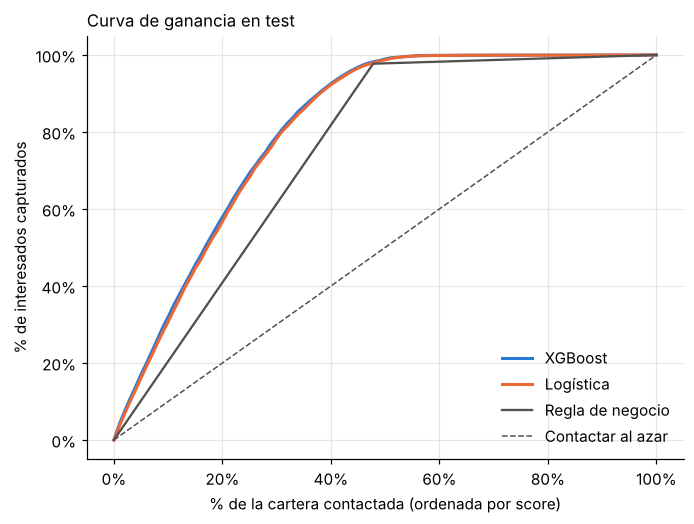

In [7]:
# Curva de ganancia: % de interesados capturados según el % de cartera contactada.
pcts = np.linspace(0, 1, 101)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pcts, [capture_at(y_test, scores["xgboost"], p) for p in pcts], color=BLUE, linewidth=2, label="XGBoost")
ax.plot(pcts, [capture_at(y_test, scores["logistica"], p) for p in pcts], color=ORANGE, linewidth=2, label="Logística")
ax.plot([0, pct_regla, 1], [0, captura_regla, 1], color=GREY, linewidth=1.5, label="Regla de negocio")
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="Contactar al azar")
ax.set_xlabel("% de la cartera contactada (ordenada por score)")
ax.set_ylabel("% de interesados capturados")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_title("Curva de ganancia en test", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.show()

**Lectura (el mensaje central para negocio):**

- **Si se contacta a toda la mitad "buena" de la cartera, el modelo apenas mejora a la regla** (98,2 % frente a 97,7 % de interesados capturados). Para ese volumen, la regla basta.
- **El modelo aporta valor cuando el presupuesto de contactos es limitado.** Con capacidad para contactar al 20 % de la cartera, el modelo captura el 57,9 % de los interesados; eligiendo al azar dentro del segmento de la regla se capturaría el 40,9 %. Son un **42 % más de interesados por el mismo coste**.
- La logística y XGBoost son casi indistinguibles en la curva.

### 4.2 Tabla de lift por deciles (XGBoost)

In [8]:
tabla = lift_table(y_test, scores["xgboost"])
tabla

,clientes,interesados,tasa_interes,lift,captura_acumulada,score_medio
tramo,,,,,,
1,7623,2990,0.3922,3.2003,0.3201,0.3866
2,7622,2421,0.3176,2.5916,0.5792,0.3152
3,7622,1957,0.2568,2.0949,0.7887,0.2579
4,7622,1279,0.1678,1.3691,0.9256,0.1718
5,7622,597,0.0783,0.6391,0.9895,0.0787
6,7623,88,0.0115,0.0942,0.9989,0.0122
7,7622,5,0.0007,0.0054,0.9995,0.0007
8,7622,1,0.0001,0.0011,0.9996,0.0005
9,7622,0,0.0000,0.0000,0.9996,0.0004


**Lectura:**

- **Decil 1:** el 39 % está interesado, 3,2 veces la tasa global. En el segmento de la regla, sin ordenar, es el 25 %.
- **Deciles 6 a 10 (la mitad de la cartera):** contienen solo el 1 % de los interesados. Se pueden descartar sin apenas pérdida.
- **Calibración:** `score_medio` y `tasa_interes` coinciden en todos los tramos (0,387 frente a 0,392 en el primero). El score se puede leer directamente como probabilidad de interés, lo que permite estimar cuántos interesados dará una campaña antes de lanzarla. Es la razón de no haber reequilibrado las clases.

## 5. ¿En qué se apoya el modelo?

Importancia por permutación sobre test: se desordena una variable cada vez y se mide cuánto cae el PR-AUC. Mide lo que el modelo **usa**, sobre las variables originales, y vale para cualquier modelo.

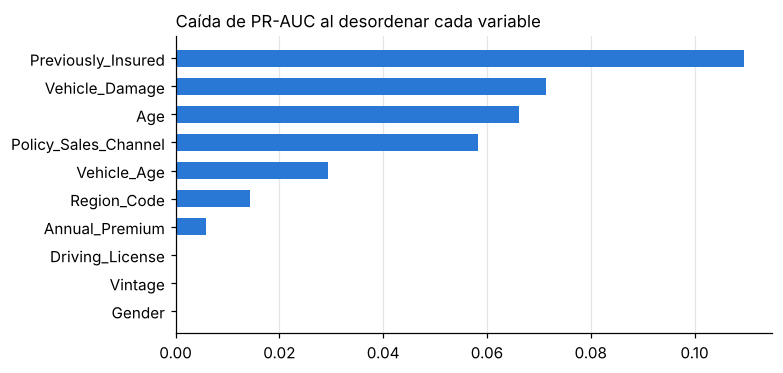

In [9]:
imp = permutation_importance(
    modelos["xgboost"], X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED
)
importancia = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importancia.index, importancia.values, color=BLUE, height=0.6)
ax.set_title("Caída de PR-AUC al desordenar cada variable", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.show()

**Lectura:**

- El modelo se apoya sobre todo en `Previously_Insured` y `Vehicle_Damage` (las variables de la regla), y después en **edad, canal de venta y antigüedad del vehículo**: son las que le permiten ordenar dentro del segmento.
- `Region_Code` y `Annual_Premium` aportan poco. `Driving_License` no aporta nada.
- `Gender` y `Vintage` salen en cero porque el modelo no las recibe.
- Precaución: canal y edad están correlacionados (visto en el EDA), así que su importancia individual está repartida entre ambas y no debe leerse como efecto causal.

## 6. Conclusiones

**Modelo elegido: XGBoost sin `Gender`.** Ordena algo mejor que la logística de forma consistente, no necesita tramos manuales de edad y sus probabilidades salen bien calibradas. La logística es una alternativa defendible si se priorizara la interpretabilidad: pierde alrededor de un punto de captura.

**Qué le diría a negocio:**

1. La mitad de la cartera (quien ya tiene seguro de vehículo o no ha tenido daños) prácticamente no tiene interesados. **No merece la pena contactarla.**
2. Si hay presupuesto para contactar a toda la otra mitad, una regla simple es suficiente.
3. Si el presupuesto es menor, **el modelo indica por dónde empezar**: en el 10 % con mayor score, 4 de cada 10 clientes están interesados.
4. El punto de corte óptimo depende del **coste por contacto y del valor de una póliza**. Con esos dos datos se puede calcular hasta qué decil es rentable llamar.

**Limitaciones:**

- `Response` es interés declarado, no contratación. El modelo predice a quién le interesa, no quién acaba comprando.
- Los datos son una foto fija: no hay fechas, así que no se puede validar en el tiempo ni saber si el comportamiento cambia entre campañas.
- El canal de venta es una variable de cómo llegó el cliente, no del cliente. Si la estrategia comercial cambia, su relación con el interés puede cambiar también; es la primera variable a vigilar en producción.

**Siguientes pasos:** ajuste de hiperparámetros con experimentos trazados, script de entrenamiento reproducible y registro del modelo.